# AVAX SHORT — Bollinger breakout + squeeze ATR (atr_ratio), train full grid trên GPU

Notebook này dùng `train_full_grid_gpu.py` cùng thư mục. Sửa **ô Cấu hình**, rồi chọn **Run All**. Mặc định là khung **1h**; có thể đổi sang `5min`, `15min`, `4h` hoặc khung cố định khác là bội số của 5 phút. Kết quả lưu thành CSV cạnh notebook.

**Logic vào lệnh tại nến `i`:** close cắt **xuống** dải dưới (`close[i-1] > lower[i] > close[i]`) **và** nến trước breakout đang ở trạng thái biến động co (squeeze):

`atr_ratio[i-1] < vol_threshold`, với `atr_ratio` = `ATR(vol_fast) / ATR(vol_slow)` (ATR Wilder).

Ratio đọc ở nến `i-1` vì chính nến breakout thường có biên độ lớn, sẽ đẩy ratio tại `i` lên và lọc mất tín hiệu. `vol_fast` < `vol_slow` (hai khoảng rời nhau). `vol_threshold = 99` là **tắt bộ lọc** — baseline để so bộ lọc có giúp hay không. Stop đặt ở dải trên × `sl_multiplier`, TP = `tp_sl_ratio` × risk, như bản RSI gốc. Mỗi bộ tham số chỉ giữ một lệnh tại một thời điểm.

Bollinger, atr_ratio và replay chạy trên GPU ở fp32; score được tính trên CPU. Đổi `SCORE_FORMULA` rồi chạy lại ô **Tính lại score** để xếp hạng lại mà không chạy lại GPU. Biến dùng được: `performance`, `max_dd`, `avg_dd`, `r2`, `number_of_trade`, `r_per_month`, `ulcer_r`, `r_martin_monthly`, `r_sharpe_monthly`.

**Lưu ý:**
- Công thức có bình phương hoặc tích hai metric (ví dụ `performance**2/...`, `r_sharpe_monthly*r_martin_monthly`) **mất dấu** — xếp cả bộ lỗ lên đầu. Mặc định dùng `r_martin_monthly` (giữ dấu).
- Grid search trên toàn bộ khoảng train là **in-sample**: bộ tốt nhất bị lạc quan do chọn lọc. Dùng ô cuối để replay trên khoảng ngày khác.
- `MAX_HOLDING_BARS` tính theo số nến của `TIMEFRAME`. Mẫu số phí tự động là số nến trong 8 giờ: `8` cho 1h, `32` cho 15 phút, `96` cho 5 phút, `2` cho 4h.
- Ô **Kiểm tra CPU** cần import `quantcrucible` (lấy từ `src/` của repo; ô nạp script tự thêm đường dẫn).

Ở ô replay cuối, đặt `BACKTEST_START_DATE` và `BACKTEST_END_DATE` để xem trial trên khoảng ngày khác với kỳ train. Để `None` nếu muốn dùng khoảng ngày train.

In [84]:
# CẤU HÌNH — sửa ô này trước khi chạy
TIMEFRAME = "15min"                    # ví dụ "5min", "15min", "1h", "4h"
START_DATE = "2024-01-01"          # ngày bắt đầu, bao gồm ngày này
END_DATE = "2025-07-01"            # ngày kết thúc, bao gồm ngày này
DATA_CSV = None                     # None = CSV 5min mặc định của script
SCRIPT_PATH = None                  # None = tự tìm train_full_grid_gpu.py

SCORE_FORMULA = "r_martin_monthly"
# Sửa trực tiếp các danh sách dưới đây để đổi grid.
# Số bộ tham số là tích số lượng giá trị trong mỗi danh sách.
# vol_fast phải nhỏ hơn vol_slow ở mọi tổ hợp; vol_threshold = 99 là tắt bộ lọc.
SEARCH_SPACES = {
    "boll_window": [6, 7, 8, 10, 12, 14, 16, 18, 20, 25, 30],
    "boll_window_dev": [2.0],
    "vol_fast": [5, 10, 14, 20, 30, 50],
    "vol_slow": [60, 100, 200, 300],
    "vol_threshold": [0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0, 99.0],
    "sl_multiplier": [0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2.0],
    "tp_sl_ratio": [1.1],
}
LIMIT = None                         # None = toàn bộ bộ tham số; số nguyên để chạy thử
MAX_HOLDING_BARS = 288             # số nến tối đa giữ lệnh theo TIMEFRAME
FEE_BARS = None                    # None = mặc định của script
VERIFY_SAMPLES = 0                  # 0 = bỏ qua so với CPU; ví dụ 8 = kiểm tra 8 bộ
MIN_TRADES = 30                     # bảng xếp hạng chỉ giữ bộ có nhiều lệnh hơn số này
OUTPUT_CSV = None                   # None = CSV theo timeframe, cạnh notebook

In [85]:
# Nạp file GPU cùng thư mục (cũng hoạt động khi kernel bắt đầu ở thư mục khác trong repo)
from pathlib import Path
import importlib.util
import itertools
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SIDE_FOLDER = "short_bollinger+atr_ratio"
if SCRIPT_PATH is None:
    candidates = []
    for parent in (Path.cwd(), *Path.cwd().parents):
        if parent.name == SIDE_FOLDER:
            candidates.append(parent / "train_full_grid_gpu.py")
        candidates.append(parent / "reference" / SIDE_FOLDER / "train_full_grid_gpu.py")
    script_path = next((path.resolve() for path in candidates if path.is_file()), None)
    if script_path is None:
        raise FileNotFoundError("Không tìm thấy train_full_grid_gpu.py; hãy đặt SCRIPT_PATH ở ô Cấu hình")
else:
    script_path = Path(SCRIPT_PATH).expanduser().resolve()
if not script_path.is_file():
    raise FileNotFoundError(script_path)

# Ô kiểm tra CPU đọc chỉ báo tham chiếu từ quantcrucible (src/ của repo).
repo_src = script_path.parents[2] / "src"
if (repo_src / "quantcrucible").is_dir() and str(repo_src) not in sys.path:
    sys.path.insert(0, str(repo_src))

spec = importlib.util.spec_from_file_location("avax_short_atr_squeeze_grid_gpu", script_path)
strategy = importlib.util.module_from_spec(spec)
spec.loader.exec_module(strategy)
csv_path = Path(DATA_CSV).expanduser().resolve() if DATA_CSV else strategy.DEFAULT_CSV
if not csv_path.is_file():
    raise FileNotFoundError(csv_path)
print("CSV:", csv_path)
print("Đã nạp:", script_path)

CSV: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+RSI\avaxusdt_futures_5min.csv
Đã nạp: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+atr_ratio\train_full_grid_gpu.py


In [86]:
# Đọc dữ liệu 5 phút, resample và tạo grid
strategy.timeframe_offset(TIMEFRAME)
default_start, default_end = strategy.default_range(TIMEFRAME)
start_date = START_DATE or default_start
end_date = END_DATE or default_end
expected_keys = set(strategy.search_space(TIMEFRAME))
space = SEARCH_SPACES
if set(space) != expected_keys:
    raise ValueError(f"SEARCH_SPACES cần đúng các khóa: {sorted(expected_keys)}")
for name, values in space.items():
    if not isinstance(values, (list, tuple)) or not values:
        raise ValueError(f"{name} phải là danh sách có ít nhất một giá trị")
space = {name: list(values) for name, values in space.items()}
if max(space["vol_fast"]) >= min(space["vol_slow"]):
    raise ValueError("Mọi vol_fast phải nhỏ hơn mọi vol_slow")

bars = strategy.load_bars(csv_path, TIMEFRAME, start_date, end_date)
combinations = itertools.product(*(space[name] for name in space))
if LIMIT is not None:
    combinations = itertools.islice(combinations, LIMIT)
grid = pd.DataFrame(combinations, columns=list(space))
print(f"Dữ liệu: {len(bars):,} nến; {bars['timestamp'].iloc[0]} → {bars['timestamp'].iloc[-1]}")
print(f"Grid: {len(grid):,} bộ tham số")
display(grid.head())

Dữ liệu: 51,508 nến; 2024-01-01 00:00:00 → 2025-06-20 12:45:00
Grid: 36,960 bộ tham số


,boll_window,boll_window_dev,vol_fast,vol_slow,vol_threshold,sl_multiplier,tp_sl_ratio
0,6,2.0,5,60,0.6,0.7,1.1
1,6,2.0,5,60,0.6,0.8,1.1
2,6,2.0,5,60,0.6,0.9,1.1
3,6,2.0,5,60,0.6,1.0,1.1
4,6,2.0,5,60,0.6,1.1,1.1


In [87]:
# Chạy toàn bộ grid trên GPU
result, timing = strategy.run_gpu_grid(
    bars, grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS,
    fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
)
print("Thời gian:", timing)
print(f"Đã tính {len(result):,} bộ tham số")

c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Thời gian: {'indicators_and_transfer_s': 0.5883528999984264, 'total_gpu_s': 2.5425131999945734}
Đã tính 36,960 bộ tham số


In [88]:
# TÍNH LẠI SCORE — chạy lại riêng ô này sau khi đổi SCORE_FORMULA
result = result.copy()
result["score"] = strategy.apply_score_formula(result, SCORE_FORMULA)
result["score_formula"] = SCORE_FORMULA
print("Score:", SCORE_FORMULA)

Score: r_martin_monthly


In [89]:
# Kiểm tra CPU (tùy chọn): đối chiếu mẫu với bản CPU fp32
if VERIFY_SAMPLES:
    strategy.verify_samples(
        bars, result, TIMEFRAME, VERIFY_SAMPLES,
        MAX_HOLDING_BARS, SCORE_FORMULA, FEE_BARS,
    )

In [90]:
# Lưu kết quả và xem các bộ tham số đứng đầu
output_path = (Path(OUTPUT_CSV).expanduser().resolve() if OUTPUT_CSV
               else script_path.with_name(f"full_gpu_grid_results_fp32_{TIMEFRAME}.csv"))
output_path.parent.mkdir(parents=True, exist_ok=True)
result.to_csv(output_path, index=False)

ranked = result.loc[(result["number_of_trade"] > MIN_TRADES) & result["score"].notna()].sort_values("score", ascending=False)

print("Đã lưu:", output_path)
print(f"Bộ có score hợp lệ và > {MIN_TRADES} lệnh: {len(ranked):,}/{len(result):,}")
display(ranked.head(20))

Đã lưu: C:\Users\Legion\Desktop\TradingProject\reference\short_bollinger+atr_ratio\full_gpu_grid_results_fp32_15min.csv
Bộ có score hợp lệ và > 30 lệnh: 29,379/36,960


,boll_window,boll_window_dev,vol_fast,vol_slow,vol_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,number_of_trade,r_per_month,ulcer_r,r_martin_monthly,r_sharpe_monthly,score,score_formula
36802,30,2.0,50,200,1.00,1.7,1.1,31.487192,5.76,1.46,0.933339,232,1.786237,1.901701,0.939284,0.490666,0.939284,r_martin_monthly
13350,10,2.0,50,300,0.75,1.5,1.1,19.857201,4.42,1.08,0.929753,70,1.126479,1.287780,0.874745,0.534149,0.874745,r_martin_monthly
13825,12,2.0,5,200,0.95,1.4,1.1,49.952110,9.81,2.45,0.967398,528,2.833733,3.297919,0.859249,0.484050,0.859249,r_martin_monthly
13828,12,2.0,5,200,0.95,1.7,1.1,44.542118,8.40,2.17,0.947293,434,2.526829,2.989687,0.845182,0.465460,0.845182,r_martin_monthly
35792,30,2.0,20,300,0.90,1.5,1.1,22.881899,5.16,1.30,0.958308,226,1.298067,1.678993,0.773123,0.364922,0.773123,r_martin_monthly
36942,30,2.0,50,300,1.00,1.7,1.1,27.358805,6.40,1.56,0.921286,223,1.552037,2.082522,0.745268,0.433465,0.745268,r_martin_monthly
13982,12,2.0,5,300,1.00,1.7,1.1,43.063435,9.43,2.54,0.950297,448,2.442945,3.344775,0.730377,0.445823,0.730377,r_martin_monthly
36800,30,2.0,50,200,1.00,1.5,1.1,24.733198,5.17,1.47,0.947293,244,1.403089,1.924818,0.728946,0.375888,0.728946,r_martin_monthly
36803,30,2.0,50,200,1.00,1.8,1.1,25.617712,5.76,1.50,0.894629,224,1.453267,2.016387,0.720728,0.414140,0.720728,r_martin_monthly
18434,14,2.0,14,300,0.90,1.7,1.1,34.332203,7.42,2.10,0.880730,335,1.947631,2.758893,0.705946,0.422624,0.705946,r_martin_monthly


,median_trades,median_performance,share_profitable,median_r_per_month,median_r_sharpe_monthly
vol_threshold,,,,,
0.60,10.0,0.000,0.289,0.000,-0.033
0.65,31.0,0.000,0.301,0.000,-0.050
0.70,66.0,-0.831,0.332,-0.047,-0.058
0.75,122.0,-1.536,0.300,-0.087,-0.064
0.80,187.0,-3.300,0.324,-0.187,-0.070
0.85,263.0,-4.924,0.272,-0.279,-0.093
0.90,329.0,-3.851,0.362,-0.218,-0.061
0.95,386.0,-3.444,0.401,-0.195,-0.048
1.00,438.0,-2.372,0.452,-0.135,-0.026


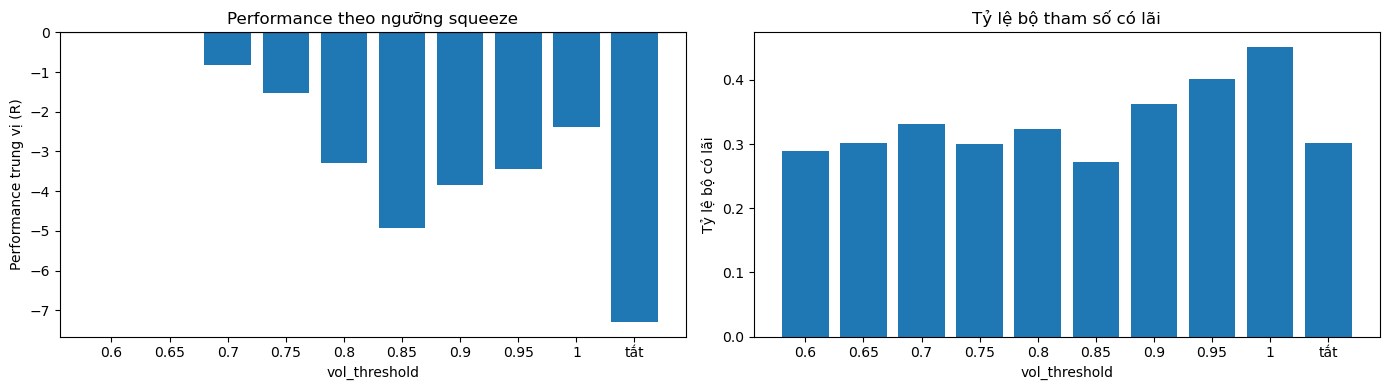

In [91]:
# Bộ lọc squeeze có giúp không? So từng vol_threshold với baseline 99 (tắt bộ lọc), trên toàn grid.
# Trung vị toàn grid ít bị nhiễu do chọn lọc hơn so với bộ "tốt nhất".
by_threshold = result.groupby("vol_threshold").agg(
    median_trades=("number_of_trade", "median"),
    median_performance=("performance", "median"),
    share_profitable=("performance", lambda s: (s > 0).mean()),
    median_r_per_month=("r_per_month", "median"),
    median_r_sharpe_monthly=("r_sharpe_monthly", "median"),
)
display(by_threshold.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
labels = [("tắt" if value >= 99 else f"{value:g}") for value in by_threshold.index]
axes[0].bar(labels, by_threshold["median_performance"])
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(xlabel="vol_threshold", ylabel="Performance trung vị (R)", title="Performance theo ngưỡng squeeze")
axes[1].bar(labels, by_threshold["share_profitable"])
axes[1].set(xlabel="vol_threshold", ylabel="Tỷ lệ bộ có lãi", title="Tỷ lệ bộ tham số có lãi")
plt.tight_layout()
plt.show()

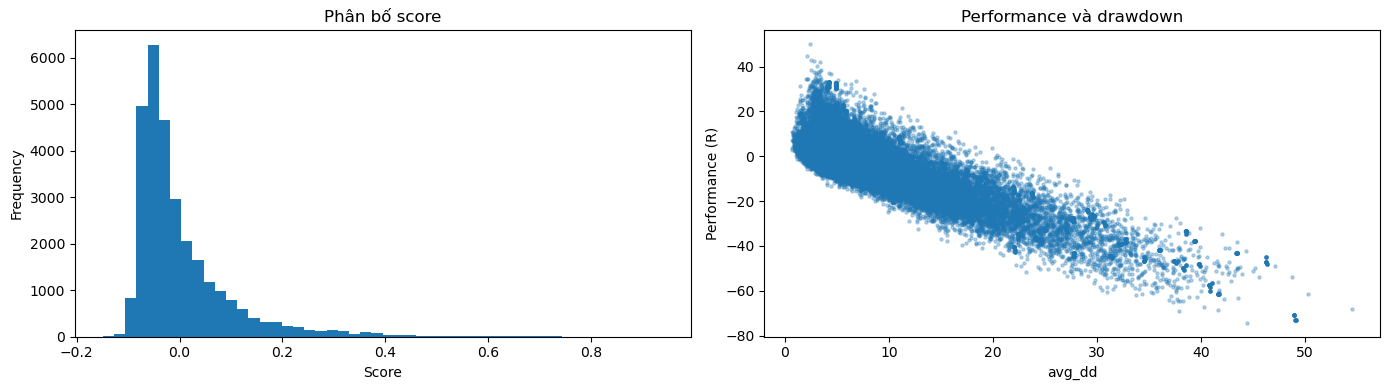

In [92]:
# Biểu đồ để xem phân bố score và hiệu quả/rủi ro của grid
if ranked.empty:
    print("Không có score hợp lệ để vẽ")
else:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    ranked["score"].plot.hist(ax=axes[0], bins=50, title="Phân bố score")
    axes[0].set_xlabel("Score")
    drawdown = "max_dd" if "max_dd" in SCORE_FORMULA else "avg_dd"
    axes[1].scatter(ranked[drawdown], ranked["performance"], s=5, alpha=0.3)
    axes[1].set(xlabel=drawdown, ylabel="Performance (R)", title="Performance và drawdown")
    plt.tight_layout()
    plt.show()

c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))
c:\Users\Legion\anaconda3\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Giai đoạn backtest: 2022-06-21 12:45:00 đến 2025-06-20 12:45:00


,boll_window,boll_window_dev,vol_fast,vol_slow,vol_threshold,sl_multiplier,tp_sl_ratio,performance,max_dd,avg_dd,r2,number_of_trade,r_per_month,ulcer_r,r_martin_monthly,r_sharpe_monthly,score,score_formula
backtest_trial,30,2.0,50,200,1.0,1.7,1.1,27.791374,19.17,5.27,0.235286,467,0.772496,7.146093,0.1081,0.217312,0.1081,r_martin_monthly


Trial 36802: 467 lệnh; performance từ lệnh = 27.791377 R; backtest GPU = 27.791374 R


,entry_price,stop_loss,take_profit,tp_sl_ratio,fee_risk_ratio,win_lose,open_timestamp,close_timestamp
0,20.760000,21.918594,19.485546,1.100000,0.023966,True,2022-06-26 15:00:00,2022-06-27 18:00:00
1,18.350000,20.137291,16.383980,1.100000,0.014534,True,2022-06-28 22:30:00,2022-06-30 07:45:00
2,16.219999,18.676346,13.518018,0.069208,0.012546,True,2022-06-30 08:00:00,2022-07-03 08:00:00
3,15.910000,16.358021,15.417176,1.100000,0.038175,False,2022-07-03 13:30:00,2022-07-03 19:30:00
4,19.860001,20.407135,19.258152,1.100000,0.037659,True,2022-07-09 23:30:00,2022-07-10 02:30:00
5,19.360001,20.997728,17.558500,1.100000,0.018175,True,2022-07-10 03:15:00,2022-07-11 22:15:00
6,17.309999,18.047264,16.499008,1.100000,0.026267,False,2022-07-12 07:00:00,2022-07-12 16:30:00
7,17.510000,18.382162,16.550621,1.100000,0.024468,True,2022-07-12 19:00:00,2022-07-13 12:30:00
8,18.930000,19.816858,17.954456,1.100000,0.023613,False,2022-07-16 06:30:00,2022-07-16 15:00:00
9,24.559999,26.009342,22.965723,1.100000,0.025418,True,2022-07-22 02:00:00,2022-07-23 18:00:00


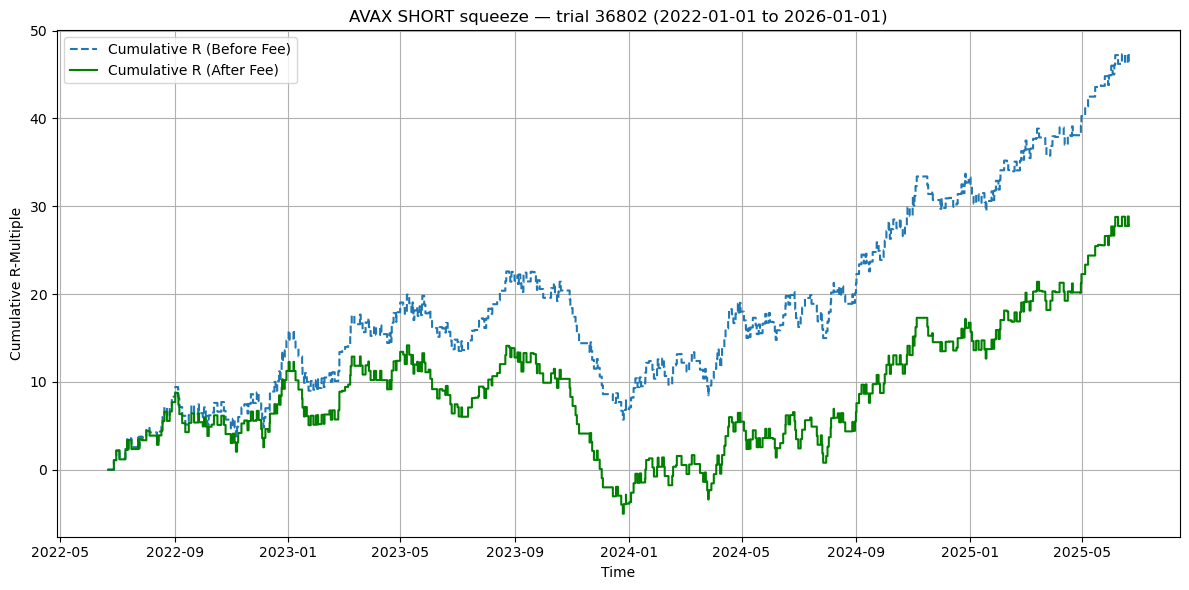

In [93]:
# Điền ID của trial trong bảng `result` (đếm từ 0), rồi chạy riêng ô này.
# Mặc định: bộ đứng đầu bảng `ranked`.
TRIAL_ID = None
BACKTEST_START_DATE = "2022-01-01"  # Ví dụ "2024-07-01"; None = ngày bắt đầu train
BACKTEST_END_DATE = "2026-01-01"    # Ví dụ "2025-07-01"; None = ngày kết thúc train

import numpy as np
import pandas as pd
from numba import cuda


@cuda.jit
def _trace_selected_trial(close, high, low, upper, lower, vol, direction,
                          threshold, multiplier, ratio,
                          max_holding_bars, fee_bars, entry_indices,
                          exit_indices, entry_prices, stop_prices, targets,
                          gross_returns, entry_fees, holding_fees, wins,
                          trade_count):
    if cuda.grid(1) != 0:
        return
    zero = np.float32(0)
    one = np.float32(1)
    n = close.size
    i = 1
    count = 0
    while i < n - 1:
        # vol[0] = chuỗi nhanh, vol[1] = chuỗi chậm; NaN hoặc mẫu số <= 0 thì không vào lệnh.
        squeezed = False
        denominator = vol[1, i - 1]
        if denominator > zero:
            squeezed = vol[0, i - 1] / denominator < threshold
        if direction == 1:
            signal = (squeezed and close[i - 1] < upper[0, i]
                      and close[i] > upper[0, i])
        else:
            signal = (squeezed and close[i - 1] > lower[0, i]
                      and close[i] < lower[0, i])
        if signal:
            entry = close[i]
            if direction == 1:
                risk = (entry - lower[0, i]) * multiplier
            else:
                risk = (upper[0, i] - entry) * multiplier
            if entry > zero and risk > zero:
                sl_price_ratio = risk / entry
                entry_fee = np.float32(0.001) / sl_price_ratio
                if entry_fee <= np.float32(0.2):
                    if direction == 1:
                        stop = entry - risk
                        target = entry + ratio * risk
                    else:
                        stop = entry + risk
                        target = entry - ratio * risk
                    j = i + 1
                    while j < n:
                        holding = j - i
                        if holding >= max_holding_bars:
                            gross = ((close[j] - entry) / risk if direction == 1
                                     else (entry - close[j]) / risk)
                            win = 1
                            break
                        if direction == 1:
                            hit_stop = low[j] <= stop
                            hit_target = high[j] >= target
                        else:
                            hit_stop = high[j] > stop
                            hit_target = low[j] < target
                        if hit_stop:
                            gross = -one
                            win = 0
                            break
                        if hit_target:
                            gross = ratio
                            win = 1
                            break
                        if j == n - 1:
                            gross = ((close[j] - entry) / risk if direction == 1
                                     else (entry - close[j]) / risk)
                            win = 1
                            break
                        j += 1
                    holding_fee = (np.float32(0.0001) *
                                   (np.float32(holding) / fee_bars) / sl_price_ratio)
                    entry_indices[count] = i
                    exit_indices[count] = j
                    entry_prices[count] = entry
                    stop_prices[count] = stop
                    targets[count] = target
                    gross_returns[count] = gross
                    entry_fees[count] = entry_fee
                    holding_fees[count] = holding_fee
                    wins[count] = win
                    count += 1
                    i = j + 1  # Không vào lệnh mới trên nến vừa thoát.
                    continue
        i += 1
    trade_count[0] = count


def plot_r_multiple_pnl(trades):
    """Đường R tích lũy trước và sau phí."""
    ordered = trades.sort_values("close_timestamp").reset_index(drop=True)
    gross = ordered["tp_sl_ratio"].where(ordered["win_lose"], -1.0)
    net = gross - ordered["fee_risk_ratio"]
    times = [ordered["close_timestamp"].iloc[0]]
    before = [0.0]
    after = [0.0]
    for timestamp, r_gross, r_net in zip(ordered["close_timestamp"], gross, net):
        times.extend((timestamp, timestamp))
        before.extend((before[-1], before[-1] + r_gross))
        after.extend((after[-1], after[-1] + r_net))
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.step(times, before, label="Cumulative R (Before Fee)", linestyle="--", where="post")
    ax.step(times, after, label="Cumulative R (After Fee)", color="green", where="post")
    ax.set(xlabel="Time", ylabel="Cumulative R-Multiple",
           title=f"AVAX {'LONG' if direction == 1 else 'SHORT'} squeeze — trial {TRIAL_ID} ({backtest_start} to {backtest_end})")
    ax.legend()
    ax.grid(True)
    fig.tight_layout()
    plt.show()


if TRIAL_ID is None:
    if ranked.empty:
        raise ValueError("Bảng ranked rỗng; hãy điền TRIAL_ID")
    TRIAL_ID = int(ranked.index[0])
if TRIAL_ID not in result.index:
    raise KeyError(f"TRIAL_ID={TRIAL_ID} không có trong result.index")
trial = result.loc[TRIAL_ID]
backtest_start = BACKTEST_START_DATE or start_date
backtest_end = BACKTEST_END_DATE or end_date
backtest_bars = (bars if BACKTEST_START_DATE is None and BACKTEST_END_DATE is None
                 else strategy.load_bars(csv_path, TIMEFRAME, backtest_start, backtest_end))
# Chỉ chạy lại một bộ tham số trên khoảng backtest; không train lại toàn bộ grid.
selected_grid = grid.loc[[TRIAL_ID]].reset_index(drop=True)
backtest_result, _ = strategy.run_gpu_grid(
    backtest_bars, selected_grid, TIMEFRAME,
    max_holding_bars=MAX_HOLDING_BARS, fee_bars=FEE_BARS,
    score_formula=SCORE_FORMULA,
)
backtest_trial = backtest_result.iloc[0]
direction = 1 if SIDE_FOLDER.startswith("long_") else -1
fee_bars = FEE_BARS
if fee_bars is None:
    fee_bars = strategy.fee_holding_divisor(TIMEFRAME)
if fee_bars <= 0:
    raise ValueError("FEE_BARS phải lớn hơn 0")

# Tính chỉ báo cho đúng bộ tham số bằng các kernel GPU đang dùng trong grid.
n = len(backtest_bars)
close32 = np.ascontiguousarray(backtest_bars["close"].to_numpy(dtype=np.float32))
high32 = np.ascontiguousarray(backtest_bars["high"].to_numpy(dtype=np.float32))
low32 = np.ascontiguousarray(backtest_bars["low"].to_numpy(dtype=np.float32))
d_close = cuda.to_device(close32)
d_high = cuda.to_device(high32)
d_low = cuda.to_device(low32)
d_upper = cuda.device_array((1, n), dtype=np.float32)
d_lower = cuda.device_array((1, n), dtype=np.float32)
d_vol = cuda.device_array((2, n), dtype=np.float32)
d_boll_window = cuda.to_device(np.array([int(trial["boll_window"])], dtype=np.int32))
d_boll_deviation = cuda.to_device(np.array([trial["boll_window_dev"]], dtype=np.float32))
d_vol_window = cuda.to_device(np.array([int(trial["vol_fast"]), int(trial["vol_slow"])], dtype=np.int32))
strategy._bollinger_windows[(n + 127) // 128, 128](
    d_close, d_boll_window, d_boll_deviation, d_upper, d_lower)
strategy._atr_windows[1, 32](d_close, d_high, d_low, d_vol_window, d_vol)

entry_indices = cuda.device_array(n, dtype=np.int32)
exit_indices = cuda.device_array(n, dtype=np.int32)
entry_prices = cuda.device_array(n, dtype=np.float32)
stop_prices = cuda.device_array(n, dtype=np.float32)
targets = cuda.device_array(n, dtype=np.float32)
gross_returns = cuda.device_array(n, dtype=np.float32)
entry_fees = cuda.device_array(n, dtype=np.float32)
holding_fees = cuda.device_array(n, dtype=np.float32)
wins = cuda.device_array(n, dtype=np.int32)
trade_count = cuda.device_array(1, dtype=np.int32)
_trace_selected_trial[1, 1](
    d_close, d_high, d_low, d_upper, d_lower, d_vol, direction,
    np.float32(trial["vol_threshold"]),
    np.float32(trial["sl_multiplier"]), np.float32(trial["tp_sl_ratio"]),
    MAX_HOLDING_BARS, np.float32(fee_bars), entry_indices,
    exit_indices, entry_prices, stop_prices, targets, gross_returns,
    entry_fees, holding_fees, wins, trade_count)
count = int(trade_count.copy_to_host()[0])
if count != int(backtest_trial["number_of_trade"]):
    raise AssertionError(f"Trial {TRIAL_ID}: backtest GPU có {backtest_trial['number_of_trade']} lệnh, replay có {count}")

entries = entry_indices.copy_to_host()[:count]
exits = exit_indices.copy_to_host()[:count]
prices = entry_prices.copy_to_host()[:count]
stops = stop_prices.copy_to_host()[:count]
take_profits = targets.copy_to_host()[:count]
gross = gross_returns.copy_to_host()[:count]
entry_costs = entry_fees.copy_to_host()[:count]
holding_costs = holding_fees.copy_to_host()[:count]
won = wins.copy_to_host()[:count]
timestamps = backtest_bars["timestamp"].to_numpy()

records = [{
    "entry_price": np.nan, "stop_loss": np.nan, "take_profit": np.nan,
    "tp_sl_ratio": 0.0, "fee_risk_ratio": 0.0, "win_lose": True,
    "open_timestamp": timestamps[0], "close_timestamp": timestamps[0],
}]
for k in range(count):
    records.append({
        "entry_price": float(prices[k]),
        "stop_loss": float(stops[k]),
        "take_profit": float(take_profits[k]),
        "tp_sl_ratio": float(gross[k] if won[k] else np.float32(trial["tp_sl_ratio"])),
        "fee_risk_ratio": float(entry_costs[k] + holding_costs[k]),
        "win_lose": bool(won[k]),
        "open_timestamp": timestamps[entries[k]],
        "close_timestamp": timestamps[exits[k]],
    })
records.append({
    "entry_price": np.nan, "stop_loss": np.nan, "take_profit": np.nan,
    "tp_sl_ratio": 0.0, "fee_risk_ratio": 0.0, "win_lose": True,
    "open_timestamp": timestamps[-1], "close_timestamp": timestamps[-1],
})
df = pd.DataFrame(records)
net_r = df["tp_sl_ratio"].where(df["win_lose"], -1.0) - df["fee_risk_ratio"]
if not np.isclose(net_r.sum(), float(backtest_trial["performance"]), rtol=1e-4, atol=1e-3):
    raise AssertionError(f"Trial {TRIAL_ID}: tổng R từ lệnh khác performance của backtest GPU")
print(f"Giai đoạn backtest: {backtest_bars['timestamp'].iloc[0]} đến {backtest_bars['timestamp'].iloc[-1]}")
display(backtest_trial.to_frame(name="backtest_trial").T)
print(f"Trial {TRIAL_ID}: {count} lệnh; performance từ lệnh = {net_r.sum():.6f} R; "
      f"backtest GPU = {backtest_trial['performance']:.6f} R")
display(df.iloc[1:-1].reset_index(drop=True).head(20))
plot_r_multiple_pnl(df)

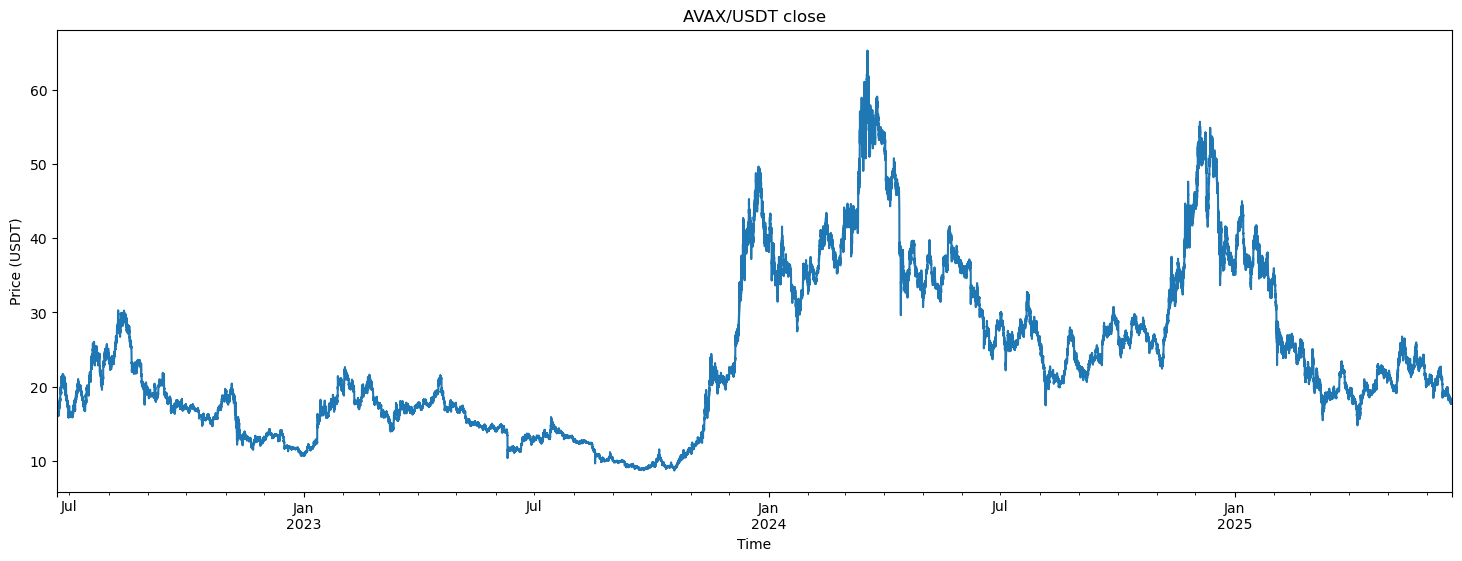

In [94]:
ax = backtest_bars.set_index("timestamp")["close"].plot(figsize=(18, 6))
ax.set(title="AVAX/USDT close", xlabel="Time", ylabel="Price (USDT)")
plt.show()